# Temperature Forecasting with DeepONet

Forecasts the next day's mean temperature in Kitchener-Waterloo from the previous 30 days, and compares DeepONet (implemented in PyTorch and in DeepXDE) with three baselines: a CNN, a ResNet and a fully connected network.

## 1. Data

Daily observations for station KITCHENER/WATERLOO (Climate ID 6144239), 2010 to 2024, from Environment and Climate Change Canada.

In [1]:
import pandas as pd
import os

# Directory containing the CSV files
directory = 'KitchenerWaterloo'

# List to hold dataframes
dataframes = []

# Loop through all files in the directory
for filename in os.listdir(directory):
    if filename.endswith('.csv'):
        file_path = os.path.join(directory, filename)
        df = pd.read_csv(file_path)
        dataframes.append(df)
        print(f'Loaded {filename}')

# Combine all dataframes into a single dataframe (optional)
combined_df = pd.concat(dataframes, ignore_index=True)

# Display the first few rows of the combined dataframe
combined_df.info()

Loaded en_climate_daily_ON_6144239_2010_P1D.csv
Loaded en_climate_daily_ON_6144239_2011_P1D.csv
Loaded en_climate_daily_ON_6144239_2012_P1D.csv
Loaded en_climate_daily_ON_6144239_2013_P1D.csv
Loaded en_climate_daily_ON_6144239_2014_P1D.csv
Loaded en_climate_daily_ON_6144239_2015_P1D.csv
Loaded en_climate_daily_ON_6144239_2016_P1D.csv
Loaded en_climate_daily_ON_6144239_2017_P1D.csv
Loaded en_climate_daily_ON_6144239_2018_P1D.csv
Loaded en_climate_daily_ON_6144239_2019_P1D.csv
Loaded en_climate_daily_ON_6144239_2020_P1D.csv
Loaded en_climate_daily_ON_6144239_2021_P1D.csv
Loaded en_climate_daily_ON_6144239_2022_P1D.csv
Loaded en_climate_daily_ON_6144239_2023_P1D.csv
Loaded en_climate_daily_ON_6144239_2024_P1D.csv
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5479 entries, 0 to 5478
Data columns (total 31 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Longitude (x)              5479 non-null   float64
 1   

### Preprocessing and 30-day windows

Keeps only the date and mean temperature, drops days with a missing temperature, and standardizes both columns (dates are first converted to day numbers). The windows are split at random, 80% for training and 20% for validation.

In [2]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, TensorDataset

# Assuming combined_df is your DataFrame with temperature data
# Extract relevant columns (e.g., Date/Time and Temperature)
data = combined_df[['Date/Time', 'Mean Temp (°C)']].dropna()

# Convert Date/Time to datetime and set as index
data['Date/Time'] = pd.to_datetime(data['Date/Time'])
data.set_index('Date/Time', inplace=True)

# Normalize the temperature data
mean_temp = data['Mean Temp (°C)'].values
mean_temp = (mean_temp - np.mean(mean_temp)) / np.std(mean_temp)

# Convert dates to numerical values
dates = data.index.map(pd.Timestamp.toordinal).values
dates = (dates - np.mean(dates)) / np.std(dates)

# Create input-output pairs for training
window_size = 30  # Number of days to use for prediction
X_dates = []
X_temps = []
y_dates = []
y_temps = []
for i in range(len(mean_temp) - window_size):
    date_window = dates[i:i + window_size]
    temp_window = mean_temp[i:i + window_size]
    future_date = dates[i + window_size]
    X_dates.append(date_window) # x1 ... x30
    X_temps.append(temp_window) # u(x1) ... u(x30)
    y_dates.append(future_date) # y
    # the above are inputs
    y_temps.append(mean_temp[i + window_size]) # G(u)(y)
    # the above is the output

X_dates = np.array(X_dates)
X_temps = np.array(X_temps)
y_dates = np.array(y_dates)
y_temps = np.array(y_temps)

# Convert to PyTorch tensors
X_dates = torch.tensor(X_dates, dtype=torch.float32)
X_temps = torch.tensor(X_temps, dtype=torch.float32)
y_dates = torch.tensor(y_dates, dtype=torch.float32).unsqueeze(1)
y_temps = torch.tensor(y_temps, dtype=torch.float32)

# Create DataLoader
dataset = TensorDataset(X_dates, X_temps, y_dates, y_temps)
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = torch.utils.data.random_split(dataset, [train_size, test_size])
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

## 2. DeepONet (PyTorch)

DeepONet learns an operator $G$ that maps an input function $u$ to an output function $G(u)$. Here $u$ is the temperature over the past 30 days, sampled at the dates $x_1, \dots, x_{30}$, and $G(u)(y)$ is the temperature on the next date $y$.

### Model

In [3]:
import torch.nn as nn
import torch.optim as optim

class DeepONet(nn.Module):
    def __init__(self, input_size):
        super(DeepONet, self).__init__()
        self.branch_net = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU()
        )
        self.trunk_net = nn.Sequential(
            nn.Linear(1, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU()
        )
        self.output_layer = nn.Linear(64, 1)

    def forward(self, branch_input, trunk_input):
        branch_output = self.branch_net(branch_input)
        trunk_output = self.trunk_net(trunk_input)
        combined = branch_output * trunk_output
        output = self.output_layer(combined)
        return output

# Initialize the model, loss function, and optimizer
input_size = window_size * 2  # 30 dates + 30 temperatures # 30 pairs of (x, u(x))
deeponet_model = DeepONet(input_size)
criterion = nn.MSELoss()
optimizer = optim.Adam(deeponet_model.parameters(), lr=0.001)

### Training

In [4]:
# Training loop for DeepONet with error tracking
num_epochs = 100
deeponet_train_losses = []
deeponet_val_losses = []

for epoch in range(num_epochs):
    deeponet_model.train()
    train_loss = 0
    for X_dates, X_temps, y_date, y_temp in train_loader:
        optimizer.zero_grad()
        branch_input = torch.cat((X_dates, X_temps), dim=1)
        trunk_input = y_date
        output = deeponet_model(branch_input, trunk_input)
        loss = criterion(output.squeeze(), y_temp)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    train_loss /= len(train_loader)
    deeponet_train_losses.append(train_loss)
    
    # Validation loss
    deeponet_model.eval()
    val_loss = 0
    with torch.no_grad():
        for X_dates, X_temps, y_date, y_temp in test_loader:
            branch_input = torch.cat((X_dates, X_temps), dim=1)
            trunk_input = y_date
            output = deeponet_model(branch_input, trunk_input)
            loss = criterion(output.squeeze(), y_temp)
            val_loss += loss.item()
    val_loss /= len(test_loader)
    deeponet_val_losses.append(val_loss)
    
    print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')

Epoch [1/100], Train Loss: 0.2925, Val Loss: 0.1748
Epoch [2/100], Train Loss: 0.1476, Val Loss: 0.1379
Epoch [3/100], Train Loss: 0.1254, Val Loss: 0.1279
Epoch [4/100], Train Loss: 0.1169, Val Loss: 0.1157
Epoch [5/100], Train Loss: 0.1096, Val Loss: 0.1155
Epoch [6/100], Train Loss: 0.1073, Val Loss: 0.1151
Epoch [7/100], Train Loss: 0.1033, Val Loss: 0.1106
Epoch [8/100], Train Loss: 0.1033, Val Loss: 0.1077
Epoch [9/100], Train Loss: 0.1050, Val Loss: 0.1168
Epoch [10/100], Train Loss: 0.1019, Val Loss: 0.1097
Epoch [11/100], Train Loss: 0.1031, Val Loss: 0.1079
Epoch [12/100], Train Loss: 0.0993, Val Loss: 0.1096
Epoch [13/100], Train Loss: 0.0995, Val Loss: 0.1107
Epoch [14/100], Train Loss: 0.0998, Val Loss: 0.1095
Epoch [15/100], Train Loss: 0.0996, Val Loss: 0.1149
Epoch [16/100], Train Loss: 0.0968, Val Loss: 0.1064
Epoch [17/100], Train Loss: 0.0995, Val Loss: 0.1095
Epoch [18/100], Train Loss: 0.0959, Val Loss: 0.1073
Epoch [19/100], Train Loss: 0.0969, Val Loss: 0.1145
Ep

### Loss curves

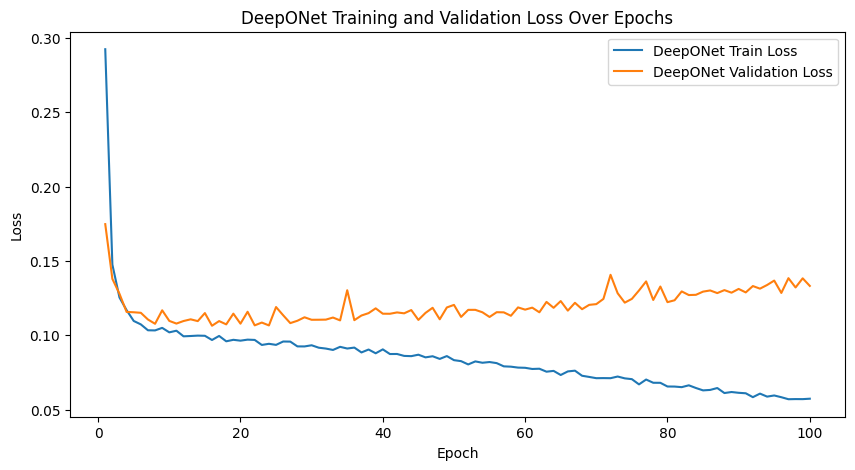

In [5]:
# Plot training and validation error
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), deeponet_train_losses, label='DeepONet Train Loss')
plt.plot(range(1, num_epochs + 1), deeponet_val_losses, label='DeepONet Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('DeepONet Training and Validation Loss Over Epochs')
plt.legend()
plt.show()

### Validation error

In [6]:
# Evaluation loop for DeepONet
deeponet_model.eval()
deeponet_predictions = []
test_error = 0
with torch.no_grad():
    for X_dates, X_temps, y_date, y_temp in test_loader:
        branch_input = torch.cat((X_dates, X_temps), dim=1)
        trunk_input = y_date
        output = deeponet_model(branch_input, trunk_input)
        deeponet_predictions.extend(output.squeeze().tolist())
        loss = criterion(output.squeeze(), y_temp)
        test_error += loss.item()

# Calculate average test error
test_error /= len(test_loader)
print(f'Test MSE for DeepONet: {test_error:.4f}')

Test MSE for DeepONet: 0.1332


## 3. CNN baseline

A 1-D convolutional network that treats the window as a sequence of length 30 with two channels (date and temperature). Three convolution layers (16, 32 and 64 channels), each followed by ReLU and max pooling, feed two fully connected layers.

### Model

In [7]:
import torch.nn as nn
import torch.optim as optim

class CNN(nn.Module):
    def __init__(self, input_size):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=2, out_channels=16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool1d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(64 * (input_size // 2 // 2 // 2), 128)
        self.fc2 = nn.Linear(128, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)  # Flatten the tensor
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Initialize the model, loss function, and optimizer
input_size = window_size  # 30 dates + 30 temperatures
cnn_model = CNN(input_size)
criterion = nn.MSELoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

### Training

In [8]:
# Training loop for CNN with error tracking
num_epochs = 100
cnn_train_losses = []
cnn_val_losses = []

for epoch in range(num_epochs):
    cnn_model.train()
    train_loss = 0
    for X_dates, X_temps, y_date, y_temp in train_loader:
        optimizer.zero_grad()
        inputs = torch.stack((X_dates, X_temps), dim=1)  # Combine dates and temperatures as channels
        output = cnn_model(inputs)
        loss = criterion(output.squeeze(), y_temp)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    train_loss /= len(train_loader)
    cnn_train_losses.append(train_loss)
    
    # Validation loss
    cnn_model.eval()
    val_loss = 0
    with torch.no_grad():
        for X_dates, X_temps, y_date, y_temp in test_loader:
            inputs = torch.stack((X_dates, X_temps), dim=1)  # Combine dates and temperatures as channels
            output = cnn_model(inputs)
            loss = criterion(output.squeeze(), y_temp)
            val_loss += loss.item()
    val_loss /= len(test_loader)
    cnn_val_losses.append(val_loss)
    
    print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')

Epoch [1/100], Train Loss: 0.2934, Val Loss: 0.2438
Epoch [2/100], Train Loss: 0.2019, Val Loss: 0.2072
Epoch [3/100], Train Loss: 0.1718, Val Loss: 0.1679
Epoch [4/100], Train Loss: 0.1550, Val Loss: 0.1682
Epoch [5/100], Train Loss: 0.1418, Val Loss: 0.1725
Epoch [6/100], Train Loss: 0.1347, Val Loss: 0.1477
Epoch [7/100], Train Loss: 0.1224, Val Loss: 0.1258
Epoch [8/100], Train Loss: 0.1209, Val Loss: 0.1290
Epoch [9/100], Train Loss: 0.1128, Val Loss: 0.1204
Epoch [10/100], Train Loss: 0.1099, Val Loss: 0.1268
Epoch [11/100], Train Loss: 0.1058, Val Loss: 0.1212
Epoch [12/100], Train Loss: 0.1030, Val Loss: 0.1216
Epoch [13/100], Train Loss: 0.1037, Val Loss: 0.1310
Epoch [14/100], Train Loss: 0.1005, Val Loss: 0.1273
Epoch [15/100], Train Loss: 0.1016, Val Loss: 0.1239
Epoch [16/100], Train Loss: 0.0992, Val Loss: 0.1223
Epoch [17/100], Train Loss: 0.0969, Val Loss: 0.1222
Epoch [18/100], Train Loss: 0.0969, Val Loss: 0.1315
Epoch [19/100], Train Loss: 0.0935, Val Loss: 0.1324
Ep

### Loss curves

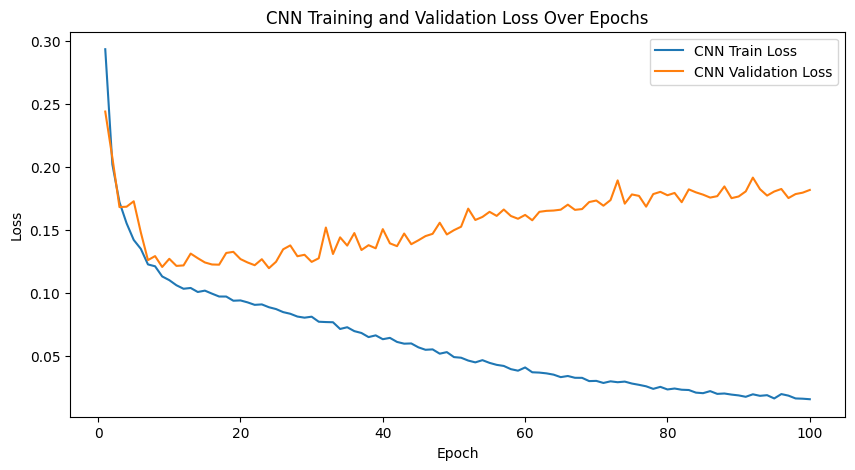

In [9]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), cnn_train_losses, label='CNN Train Loss')
plt.plot(range(1, num_epochs + 1), cnn_val_losses, label='CNN Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('CNN Training and Validation Loss Over Epochs')
plt.legend()
plt.show()

### Validation error

In [10]:
# Evaluation loop for CNN
cnn_model.eval()
cnn_predictions = []
test_error = 0
with torch.no_grad():
    for X_dates, X_temps, y_date, y_temp in test_loader:
        inputs = torch.stack((X_dates, X_temps), dim=1)  # Combine dates and temperatures as channels
        output = cnn_model(inputs)
        cnn_predictions.extend(output.squeeze().tolist())
        loss = criterion(output.squeeze(), y_temp)
        test_error += loss.item()

# Calculate average test error
test_error /= len(test_loader)
print(f'Test MSE for CNN: {test_error:.4f}')

Test MSE for CNN: 0.1815


## 4. ResNet baseline

A 1-D residual network: a stem convolution and max pooling, then three stages of two residual blocks (16, 32 and 64 channels) with batch normalization, then global average pooling and a linear output. Inputs are the same two-channel windows as the CNN.

### Model

In [11]:
import torch.nn as nn
import torch.optim as optim

class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(BasicBlock, self).__init__()
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm1d(out_channels)
        self.downsample = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.downsample = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1, stride=stride),
                nn.BatchNorm1d(out_channels)
            )

    def forward(self, x):
        identity = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        out += self.downsample(identity)
        out = self.relu(out)
        return out

class ResNet(nn.Module):
    def __init__(self, block, layers, input_size):
        super(ResNet, self).__init__()
        self.in_channels = 16
        self.conv1 = nn.Conv1d(2, 16, kernel_size=7, stride=2, padding=3)
        self.bn1 = nn.BatchNorm1d(16)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)
        self.layer1 = self._make_layer(block, 16, layers[0])
        self.layer2 = self._make_layer(block, 32, layers[1], stride=2)
        self.layer3 = self._make_layer(block, 64, layers[2], stride=2)
        self.avgpool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(64, 1)

    def _make_layer(self, block, out_channels, blocks, stride=1):
        layers = []
        layers.append(block(self.in_channels, out_channels, stride))
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(block(out_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.avgpool(x)
        x = x.view(x.size(0), -1)  # Flatten the tensor
        x = self.fc(x)
        return x

# Initialize the model, loss function, and optimizer
input_size = window_size  # 30 dates + 30 temperatures
resnet_model = ResNet(BasicBlock, [2, 2, 2], input_size)
criterion = nn.MSELoss()
optimizer = optim.Adam(resnet_model.parameters(), lr=0.001)

### Training

In [12]:
# Training loop for ResNet with error tracking
num_epochs = 100
resnet_train_losses = []
resnet_val_losses = []

for epoch in range(num_epochs):
    resnet_model.train()
    train_loss = 0
    for X_dates, X_temps, y_date, y_temp in train_loader:
        optimizer.zero_grad()
        inputs = torch.stack((X_dates, X_temps), dim=1)  # Combine dates and temperatures as channels
        output = resnet_model(inputs)
        loss = criterion(output.squeeze(), y_temp)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    train_loss /= len(train_loader)
    resnet_train_losses.append(train_loss)
    
    # Validation loss
    resnet_model.eval()
    val_loss = 0
    with torch.no_grad():
        for X_dates, X_temps, y_date, y_temp in test_loader:
            inputs = torch.stack((X_dates, X_temps), dim=1)  # Combine dates and temperatures as channels
            output = resnet_model(inputs)
            loss = criterion(output.squeeze(), y_temp)
            val_loss += loss.item()
    val_loss /= len(test_loader)
    resnet_val_losses.append(val_loss)
    
    print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')

Epoch [1/100], Train Loss: 0.2723, Val Loss: 0.1669
Epoch [2/100], Train Loss: 0.1896, Val Loss: 0.1674
Epoch [3/100], Train Loss: 0.1653, Val Loss: 0.1447
Epoch [4/100], Train Loss: 0.1459, Val Loss: 0.1432
Epoch [5/100], Train Loss: 0.1344, Val Loss: 0.1454
Epoch [6/100], Train Loss: 0.1302, Val Loss: 0.1240
Epoch [7/100], Train Loss: 0.1316, Val Loss: 0.1190
Epoch [8/100], Train Loss: 0.1203, Val Loss: 0.1388
Epoch [9/100], Train Loss: 0.1238, Val Loss: 0.1293
Epoch [10/100], Train Loss: 0.1201, Val Loss: 0.1375
Epoch [11/100], Train Loss: 0.1131, Val Loss: 0.1358
Epoch [12/100], Train Loss: 0.1212, Val Loss: 0.1284
Epoch [13/100], Train Loss: 0.1072, Val Loss: 0.1266
Epoch [14/100], Train Loss: 0.1050, Val Loss: 0.1299
Epoch [15/100], Train Loss: 0.1018, Val Loss: 0.1313
Epoch [16/100], Train Loss: 0.1011, Val Loss: 0.1368
Epoch [17/100], Train Loss: 0.0972, Val Loss: 0.1211
Epoch [18/100], Train Loss: 0.0954, Val Loss: 0.1208
Epoch [19/100], Train Loss: 0.0982, Val Loss: 0.1315
Ep

### Loss curves

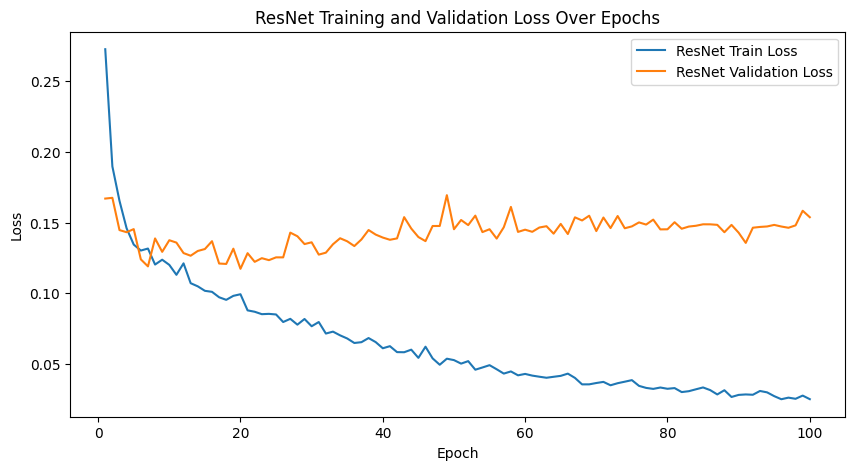

In [13]:
# Plot training and validation error for ResNet
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), resnet_train_losses, label='ResNet Train Loss')
plt.plot(range(1, num_epochs + 1), resnet_val_losses, label='ResNet Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('ResNet Training and Validation Loss Over Epochs')
plt.legend()
plt.show()

### Validation error

In [14]:
# Evaluation loop for ResNet
resnet_model.eval()
resnet_predictions = []
test_error = 0
with torch.no_grad():
    for X_dates, X_temps, y_date, y_temp in test_loader:
        inputs = torch.stack((X_dates, X_temps), dim=1)  # Combine dates and temperatures as channels
        output = resnet_model(inputs)
        resnet_predictions.extend(output.squeeze().tolist())
        loss = criterion(output.squeeze(), y_temp)
        test_error += loss.item()

# Calculate average test error
test_error /= len(test_loader)
print(f'Test MSE for ResNet: {test_error:.4f}')

Test MSE for ResNet: 0.1537


## 5. Fully connected network baseline

A plain multilayer perceptron with the same 60 inputs as the DeepONet branch net (30 dates and 30 temperatures), hidden layers of 128 and 64 units with ReLU, and one output.

### Model

In [15]:
import torch.nn as nn
import torch.optim as optim

class FullyConnectedNN(nn.Module):
    def __init__(self, input_size):
        super(FullyConnectedNN, self).__init__()
        self.fc1 = nn.Linear(input_size, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# Initialize the model, loss function, and optimizer
input_size = window_size * 2  # 30 dates + 30 temperatures
fc_model = FullyConnectedNN(input_size)
criterion = nn.MSELoss()
optimizer = optim.Adam(fc_model.parameters(), lr=0.001)

### Training

In [16]:
# Training loop for Fully Connected Model
num_epochs = 100
fc_train_losses = []
fc_val_losses = []

for epoch in range(num_epochs):
    fc_model.train()
    train_loss = 0
    for X_dates, X_temps, y_date, y_temp in train_loader:
        optimizer.zero_grad()
        inputs = torch.cat((X_dates, X_temps), dim=1)  # Combine dates and temperatures
        output = fc_model(inputs)
        loss = criterion(output.squeeze(), y_temp)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    train_loss /= len(train_loader)
    fc_train_losses.append(train_loss)
    
    # Validation loss
    fc_model.eval()
    val_loss = 0
    with torch.no_grad():
        for X_dates, X_temps, y_date, y_temp in test_loader:
            inputs = torch.cat((X_dates, X_temps), dim=1)  # Combine dates and temperatures
            output = fc_model(inputs)
            loss = criterion(output.squeeze(), y_temp)
            val_loss += loss.item()
    val_loss /= len(test_loader)
    fc_val_losses.append(val_loss)
    
    print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')

Epoch [1/100], Train Loss: 0.2327, Val Loss: 0.1497
Epoch [2/100], Train Loss: 0.1318, Val Loss: 0.1289
Epoch [3/100], Train Loss: 0.1169, Val Loss: 0.1205
Epoch [4/100], Train Loss: 0.1111, Val Loss: 0.1187
Epoch [5/100], Train Loss: 0.1059, Val Loss: 0.1055
Epoch [6/100], Train Loss: 0.1032, Val Loss: 0.1122
Epoch [7/100], Train Loss: 0.1046, Val Loss: 0.1076
Epoch [8/100], Train Loss: 0.1026, Val Loss: 0.1085
Epoch [9/100], Train Loss: 0.1019, Val Loss: 0.1101
Epoch [10/100], Train Loss: 0.1013, Val Loss: 0.1060
Epoch [11/100], Train Loss: 0.1000, Val Loss: 0.1072
Epoch [12/100], Train Loss: 0.1014, Val Loss: 0.1130
Epoch [13/100], Train Loss: 0.0999, Val Loss: 0.1080
Epoch [14/100], Train Loss: 0.0964, Val Loss: 0.1087
Epoch [15/100], Train Loss: 0.0974, Val Loss: 0.1076
Epoch [16/100], Train Loss: 0.0956, Val Loss: 0.1085
Epoch [17/100], Train Loss: 0.0974, Val Loss: 0.1078
Epoch [18/100], Train Loss: 0.0969, Val Loss: 0.1069
Epoch [19/100], Train Loss: 0.0973, Val Loss: 0.1094
Ep

### Loss curves

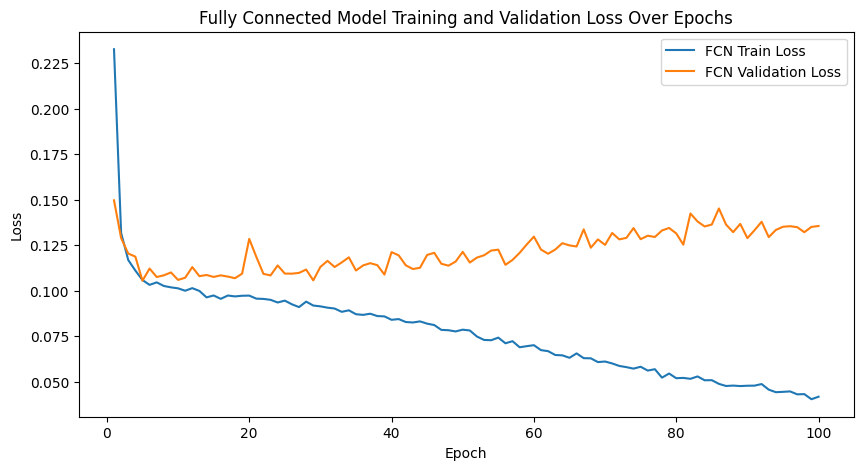

In [17]:
# Plot training and validation error for Fully Connected Model
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), fc_train_losses, label='FCN Train Loss')
plt.plot(range(1, num_epochs + 1), fc_val_losses, label='FCN Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Fully Connected Model Training and Validation Loss Over Epochs')
plt.legend()
plt.show()

### Validation error

In [18]:
# Evaluation loop for Fully Connected Model
fc_model.eval()
fc_predictions = []
test_error = 0
with torch.no_grad():
    for X_dates, X_temps, y_date, y_temp in test_loader:
        inputs = torch.cat((X_dates, X_temps), dim=1)  # Combine dates and temperatures
        output = fc_model(inputs)
        fc_predictions.extend(output.squeeze().tolist())
        loss = criterion(output.squeeze(), y_temp)
        test_error += loss.item()

# Calculate average test error
test_error /= len(test_loader)
print(f'Test MSE for Fully Connected Model: {test_error:.4f}')

Test MSE for Fully Connected Model: 0.1356


## 6. DeepONet (DeepXDE)

The same DeepONet, built with `dde.maps.OpNN` from DeepXDE 0.11.2, the library used by the original DeepONet paper. It uses the same split, layer sizes, activation and learning rate as the PyTorch version.

### Convert the data for DeepXDE

In [ ]:
import deepxde as dde
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [20]:
# Restructuring the data into numpy arrays for deepxde
X_train_deepxde = [[],[]]
y_train_deepxde = []
for i in train_dataset:
    X_train_deepxde[0].append(np.concatenate([i[0].numpy(), i[1].numpy()]))
    X_train_deepxde[1].append(i[2].numpy())
    y_train_deepxde.append(i[3].numpy())

X_train_deepxde[0] = np.array(X_train_deepxde[0])
X_train_deepxde[1] = np.array(X_train_deepxde[1])
y_train_deepxde = np.array(y_train_deepxde)
y_train_deepxde = y_train_deepxde.reshape(-1,1)

X_test_deepxde = [[],[]]
y_test_deepxde = []
for i in test_dataset:
    X_test_deepxde[0].append(np.concatenate([i[0].numpy(), i[1].numpy()]))
    X_test_deepxde[1].append(i[2].numpy())
    y_test_deepxde.append(i[3].numpy())

X_test_deepxde[0] = np.array(X_test_deepxde[0])
X_test_deepxde[1] = np.array(X_test_deepxde[1])
y_test_deepxde = np.array(y_test_deepxde)
y_test_deepxde = y_test_deepxde.reshape(-1,1)



### Build the model

In [21]:
# Defining dde data loader
data = dde.data.OpDataSet(
    X_train=X_train_deepxde,
    y_train=y_train_deepxde,
    X_test=X_test_deepxde,
    y_test=y_test_deepxde,
    standardize=False
)

In [22]:
# Model Parameters
activation = "relu"
initializer = "Glorot normal"
metrics = []
lr = 0.001
epochs = num_epochs

dim_X = 2*window_size   # dimension of X 
dim_Y = 1               # dimension of y 
brand_trunk_width = 64

net = dde.maps.OpNN(
            [dim_X, 64, brand_trunk_width], # Branch layer size
            [dim_Y, 64, brand_trunk_width], # Trunk layer size
            activation,
            initializer,
            use_bias=False,
            stacked=False,
        )

### Training

In [23]:
# Training
model = dde.Model(data, net)
model.compile("adam", lr=lr, metrics=metrics)
checker = dde.callbacks.ModelCheckpoint("model/model.ckpt", save_better_only=True, period=1000)
losshistory, train_state = model.train(epochs=epochs, callbacks=[checker], display_every=1, batch_size=32)

# Saving results
dde.saveplot(losshistory, train_state, issave=True, isplot=False)

Compiling model...
Building operator neural network...


f:\Resume\Github Projects\4.AMATH900-DeepONet-Weather-Forecasting\Github\DeepONet-Weather-Forecasting\.venv\Lib\site-packages\deepxde\maps\opnn.py:183: UserWarning: `tf.layers.dense` is deprecated and will be removed in a future version. Please use `tf.keras.layers.Dense` instead.
  return tf.layers.dense(



'build' took 0.553824 s


'compile' took 1.199506 s

Initializing variables...
Training model...

Step      Train loss    Test loss     Test metric
0         [1.34e+00]    [1.28e+00]    []  
1         [1.04e+00]    [1.03e+00]    []  
2         [8.40e-01]    [8.49e-01]    []  
3         [6.36e-01]    [7.34e-01]    []  
4         [3.64e-01]    [6.76e-01]    []  
5         [4.05e-01]    [6.24e-01]    []  
6         [3.60e-01]    [5.93e-01]    []  
7         [5.25e-01]    [5.71e-01]    []  
8         [4.94e-01]    [5.73e-01]    []  
9         [4.11e-01]    [5.96e-01]    []  
10        [3.22e-01]    [6.28e-01]    []  
11        [5.14e-01]    [6.39e-01]    []  
12        [5.31e-01]    [6.17e-01]    []  
13        [5.80e-01]    [5.92e-01]    []  
14        [6.24e-01]    [5.77e-01]    []  
15        [4.36e-01]    [5.53e-01]    []  
16        [2.14e-01]    [5.32e-01]    []  
17        [4.06e-01]    [5.08e-01]    []  
18        [4.92e-01]    [4.86e-01]    []  
19        [3.29e-01]    [4.67e-01]

### Loss curves

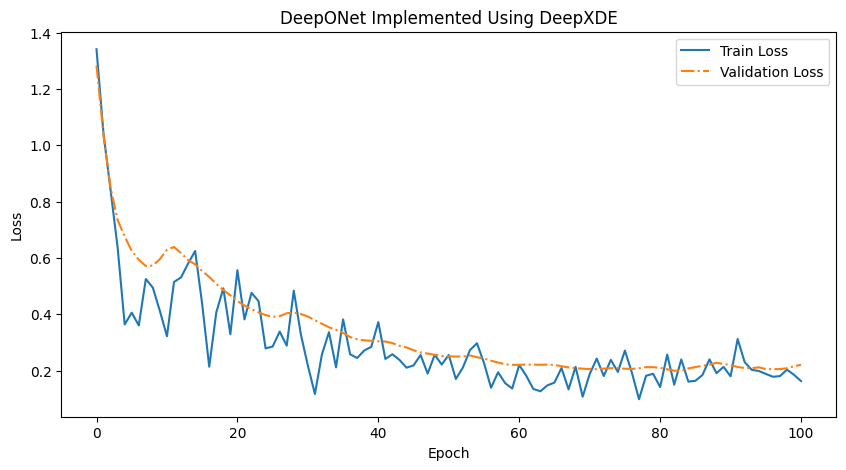

In [24]:
# Plotting
data = pd.read_csv("loss.dat", sep='\s+')
num_steps = data["#"] 
train_loss_deepxde = data["step,"] # The headers and rest of data use different deliminators
test_loss_deepxde = data["loss_train,"]


plt.figure(figsize=(10, 5))
plt.plot(num_steps, train_loss_deepxde, label="Train Loss")
plt.plot(num_steps, test_loss_deepxde, label="Validation Loss", linestyle='dashdot')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('DeepONet Implemented Using DeepXDE')
plt.legend()
plt.show()

## 7. Comparison

All five models are evaluated on the same validation set. The box plot shows the absolute error of each prediction, the bar chart shows each model's validation MSE, and the last cells compare the loss curves. Temperatures are standardized, so errors are in standard deviations of daily mean temperature.

### Error by model

C:\Users\lix77\AppData\Local\Temp\ipykernel_18532\3489307038.py:35: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([cnn_deviation, resnet_deviation, deeponet_deviation, fc_deviation, deepxde_deviation],


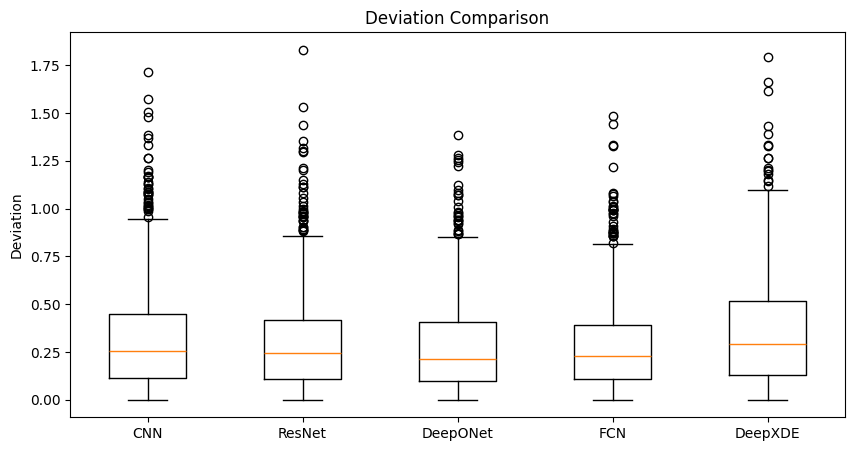

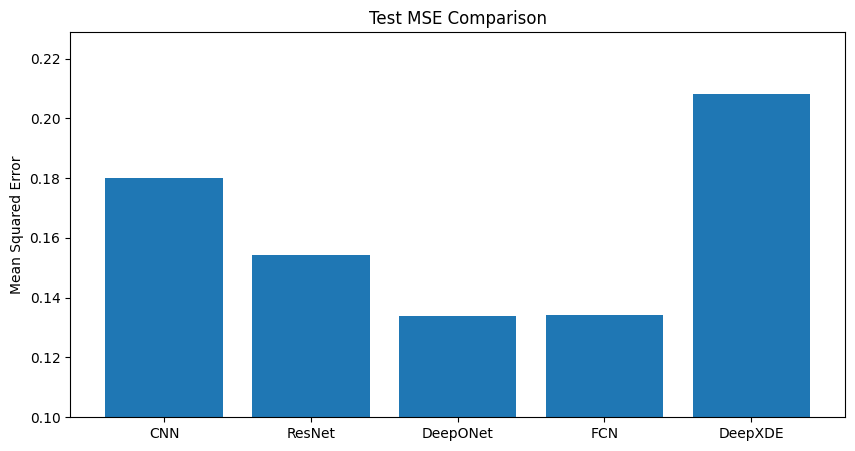

In [25]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_squared_error
import os

# Folder for the figures used in the README
os.makedirs('figures', exist_ok=True)

# Extract true temperature values from the test dataset
y_test = []
for _, _, _, y_temp in test_loader:
    y_test.extend(y_temp.tolist())
y_test = np.array(y_test)

# Calculate the MSE for each model
cnn_mse = mean_squared_error(y_test, cnn_predictions)
resnet_mse = mean_squared_error(y_test, resnet_predictions)
deeponet_mse = mean_squared_error(y_test, deeponet_predictions)
fc_mse = mean_squared_error(y_test, fc_predictions)

# Collect the MSE values
mse_values = [cnn_mse, resnet_mse, deeponet_mse, fc_mse, train_state.best_loss_test]
model_names = ['CNN', 'ResNet', 'DeepONet', 'FCN', 'DeepXDE']

# Calculate deviations
cnn_deviation = np.abs(np.array(y_test) - np.array(cnn_predictions))
resnet_deviation = np.abs(np.array(y_test) - np.array(resnet_predictions))
deeponet_deviation = np.abs(np.array(y_test) - np.array(deeponet_predictions))
fc_deviation = np.abs(np.array(y_test) - np.array(fc_predictions))
deepxde_deviation = np.abs(y_test_deepxde - np.array(train_state.best_y))
deepxde_deviation = deepxde_deviation.reshape(-1)

# Boxplot of deviations
plt.figure(figsize=(10, 5))
plt.boxplot([cnn_deviation, resnet_deviation, deeponet_deviation, fc_deviation, deepxde_deviation], 
            labels=['CNN', 'ResNet', 'DeepONet', 'FCN', 'DeepXDE'])
plt.title('Deviation Comparison')
plt.ylabel('Deviation')
plt.savefig('figures/deviation_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

# Bar plot of test MSE errors with y-axis starting from 0.1
plt.figure(figsize=(10, 5))
plt.bar(model_names, mse_values)
plt.title('Test MSE Comparison')
plt.ylabel('Mean Squared Error')
plt.ylim(0.1, max(mse_values) * 1.1)  # Set y-axis to start from 0.1
plt.show()

### Loss curves by model

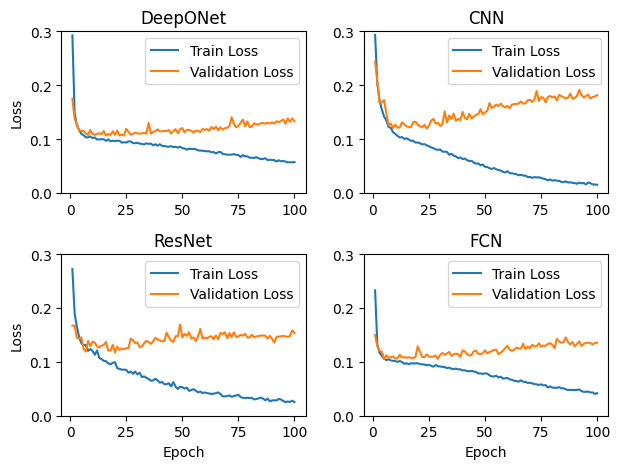

In [26]:
# Generating the previous graphs as a single figure
fig, axs = plt.subplots(2,2)

axs[0, 0].plot(range(1, num_epochs + 1), deeponet_train_losses, label='Train Loss')
axs[0, 0].plot(range(1, num_epochs + 1), deeponet_val_losses, label='Validation Loss')
axs[0, 0].set(ylabel='Loss')
axs[0, 0].set_title('DeepONet')
axs[0, 0].legend()

axs[0, 1].plot(range(1, num_epochs + 1), cnn_train_losses, label='Train Loss')
axs[0, 1].plot(range(1, num_epochs + 1), cnn_val_losses, label='Validation Loss')
axs[0, 1].set_title('CNN')
axs[0, 1].legend()

axs[1, 0].plot(range(1, num_epochs + 1), resnet_train_losses, label='Train Loss')
axs[1, 0].plot(range(1, num_epochs + 1), resnet_val_losses, label='Validation Loss')
axs[1, 0].set(xlabel='Epoch', ylabel='Loss')
axs[1, 0].set_title('ResNet')
axs[1, 0].legend()

# Plot training and validation error for Fully Connected Model
axs[1, 1].plot(range(1, num_epochs + 1), fc_train_losses, label='Train Loss')
axs[1, 1].plot(range(1, num_epochs + 1), fc_val_losses, label='Validation Loss')
axs[1, 1].set(xlabel='Epoch')
axs[1, 1].set_title('FCN')
axs[1, 1].legend()

axs[0, 0].set_ylim([0,0.3])
axs[0, 1].set_ylim([0,0.3])
axs[1, 0].set_ylim([0,0.3])
axs[1, 1].set_ylim([0,0.3])

# Lay out the panels after they are drawn, then save the figure used in the README
fig.tight_layout()
fig.savefig('figures/loss_curves.png', dpi=150, bbox_inches='tight')

### All models together

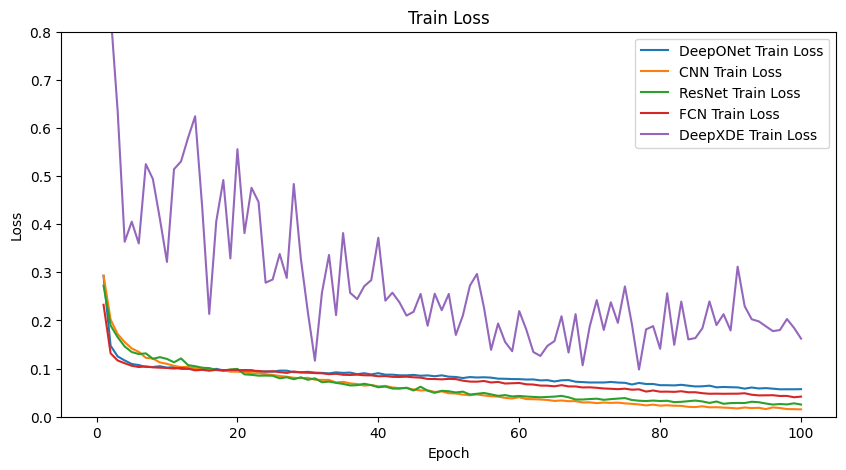

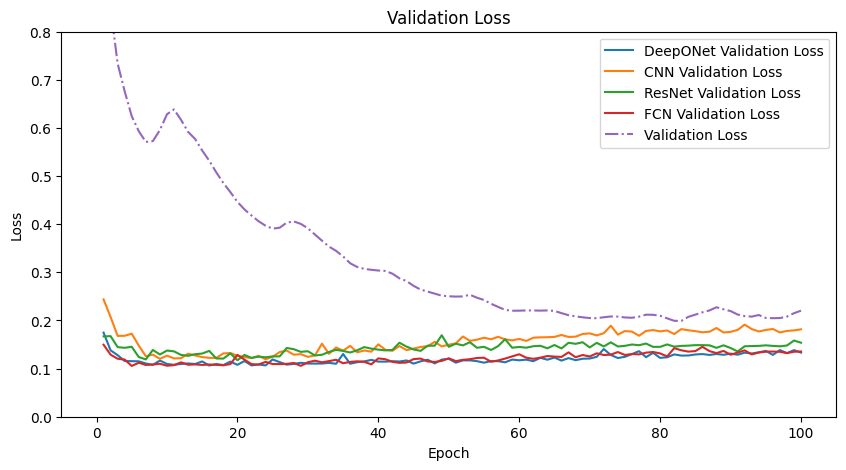

In [27]:
# Putting the previous graphs together
plt.figure(figsize=(10, 5))
plt.title("Train Loss")
plt.plot(range(1, num_epochs + 1), deeponet_train_losses, label='DeepONet Train Loss')
plt.plot(range(1, num_epochs + 1), cnn_train_losses, label='CNN Train Loss')
plt.plot(range(1, num_epochs + 1), resnet_train_losses, label='ResNet Train Loss')
plt.plot(range(1, num_epochs + 1), fc_train_losses, label='FCN Train Loss')
plt.plot(num_steps, train_loss_deepxde, label="DeepXDE Train Loss")
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim([0,0.8])
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.title("Validation Loss")
plt.plot(range(1, num_epochs + 1), deeponet_val_losses, label='DeepONet Validation Loss')
plt.plot(range(1, num_epochs + 1), cnn_val_losses, label='CNN Validation Loss')
plt.plot(range(1, num_epochs + 1), resnet_val_losses, label='ResNet Validation Loss')
plt.plot(range(1, num_epochs + 1), fc_val_losses, label='FCN Validation Loss')
plt.plot(num_steps, test_loss_deepxde, label="Validation Loss", linestyle='dashdot')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim([0,0.8])
plt.legend()
plt.show()
